In [1]:

import requests
import pandas as pandita

# URL inicial
url = 'https://rickandmortyapi.com/api/character'

# Lista para guardar los personajes
lista_personajes = []

# Recorrer todas las páginas
while url:
    respuesta = requests.get(url)
    datos = respuesta.json()

    # Agregar personajes
    lista_personajes.extend(datos['results'])

    # Obtener la siguiente página
    url = datos['info']['next']

# Crear DataFrame
df = pandita.DataFrame(lista_personajes)

print("Cantidad de personajes:", len(df))

display(df.head())


Cantidad de personajes: 826


,id,name,status,species,type,gender,origin,location,image,episode,url,created
0,1,Rick Sanchez,Alive,Human,,Male,"{'name': 'Earth (C-137)', 'url': 'https://rick...","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/1, ht...",https://rickandmortyapi.com/api/character/1,2017-11-04T18:48:46.250Z
1,2,Morty Smith,Alive,Human,,Male,"{'name': 'unknown', 'url': ''}","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/1, ht...",https://rickandmortyapi.com/api/character/2,2017-11-04T18:50:21.651Z
2,3,Summer Smith,Alive,Human,,Female,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/3,2017-11-04T19:09:56.428Z
3,4,Beth Smith,Alive,Human,,Female,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/4,2017-11-04T19:22:43.665Z
4,5,Jerry Smith,Alive,Human,,Male,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/5,2017-11-04T19:26:56.301Z


In [2]:

# Crear un nuevo DataFrame
df_ml = pandita.DataFrame({
    'nombre': df['name'],
    'estado': df['status'],
    'especie': df['species'],
    'genero': df['gender'],
    'origen': df['origin'].apply(lambda x: x['name']),
    'ubicacion': df['location'].apply(lambda x: x['name'])
})

# Mostrar información
display(df_ml.head())

# Revisar columnas
df_ml.info()


,nombre,estado,especie,genero,origen,ubicacion
0,Rick Sanchez,Alive,Human,Male,Earth (C-137),Citadel of Ricks
1,Morty Smith,Alive,Human,Male,unknown,Citadel of Ricks
2,Summer Smith,Alive,Human,Female,Earth (Replacement Dimension),Earth (Replacement Dimension)
3,Beth Smith,Alive,Human,Female,Earth (Replacement Dimension),Earth (Replacement Dimension)
4,Jerry Smith,Alive,Human,Male,Earth (Replacement Dimension),Earth (Replacement Dimension)


<class 'pandas.DataFrame'>
RangeIndex: 826 entries, 0 to 825
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   nombre     826 non-null    str  
 1   estado     826 non-null    str  
 2   especie    826 non-null    str  
 3   genero     826 non-null    str  
 4   origen     826 non-null    str  
 5   ubicacion  826 non-null    str  
dtypes: str(6)
memory usage: 38.8 KB


In [3]:

# Eliminar registros con estado desconocido
df_ml = df_ml[df_ml['estado'] != 'unknown'].copy()

# Revisar las categorías
print(df_ml['estado'].value_counts())


estado
Alive    439
Dead     287
Name: count, dtype: int64


In [4]:

# Variable objetivo
y = df_ml['estado']

# Variables predictoras
X = df_ml.drop(['estado', 'nombre'], axis=1)

# Convertir variables categóricas en números
X = pandita.get_dummies(X, dtype=int)

display(X.head())


,especie_Alien,especie_Animal,especie_Cronenberg,especie_Disease,especie_Human,especie_Humanoid,especie_Mythological Creature,especie_Poopybutthole,especie_Robot,especie_unknown,...,ubicacion_The Menagerie,ubicacion_Tickets Please Guy Nightmare,ubicacion_Unity's Planet,ubicacion_Venzenulon 7,ubicacion_Vindicator's Base,ubicacion_Worldender's lair,ubicacion_Z. Q. P. D.,ubicacion_Zeep Xanflorp's Miniverse,ubicacion_Zigerion's Base,ubicacion_unknown
0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Dividir datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Crear el modelo
modelo = RandomForestClassifier(random_state=42)

# Entrenar
modelo.fit(X_train, y_train)

# Realizar predicciones
predicciones = modelo.predict(X_test)

# Evaluar el modelo
print("Exactitud del modelo:")
print(accuracy_score(y_test, predicciones))

print("\nReporte de clasificación:")
print(classification_report(y_test, predicciones))


Exactitud del modelo:
0.7191780821917808

Reporte de clasificación:
              precision    recall  f1-score   support

       Alive       0.77      0.76      0.77        88
        Dead       0.64      0.66      0.65        58

    accuracy                           0.72       146
   macro avg       0.71      0.71      0.71       146
weighted avg       0.72      0.72      0.72       146



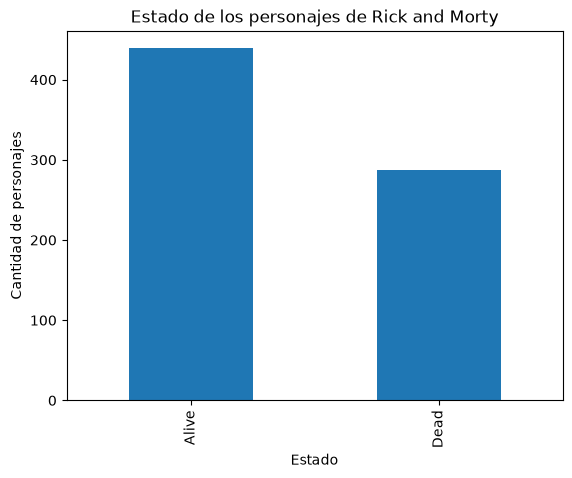

In [6]:

import matplotlib.pyplot as plt

df_ml['estado'].value_counts().plot(
    kind='bar',
    title='Estado de los personajes de Rick and Morty'
)

plt.xlabel('Estado')
plt.ylabel('Cantidad de personajes')
plt.show()
